In [1]:
# performing standardization

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rakeshrau/social-network-ads")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3.27k/3.27k [00:00<00:00, 1.65MB/s]

Extracting files...


In [25]:
df = pd.read_csv(f'{path}/Social_Network_Ads.csv')

In [26]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [27]:
df = df[['Age', 'EstimatedSalary', 'Purchased']]

In [28]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [29]:
from sklearn.model_selection import train_test_split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns= 'Purchased'), df['Purchased'], test_size= 0.2, random_state= 42)

In [31]:
X_train.head()

,Age,EstimatedSalary
3,27,57000
18,46,28000
202,39,134000
250,44,39000
274,57,26000


In [32]:
X_train.describe()

,Age,EstimatedSalary
count,320.000000,320.00000
mean,37.871875,70281.25000
std,10.207525,34430.55286
min,18.000000,15000.00000
25%,30.000000,43000.00000
50%,37.000000,71000.00000
75%,45.000000,88000.00000
max,60.000000,150000.00000


In [33]:
from sklearn.preprocessing import StandardScaler

In [34]:
std = StandardScaler()

In [35]:
std.fit(X_train)

,copy,True
,with_mean,True
,with_std,True


In [36]:
std.mean_

array([3.7871875e+01, 7.0281250e+04])

In [37]:
std.var_

array([1.03867959e+02, 1.18175840e+09])

In [38]:
X_train_trans = std.transform(X_train)
X_test_trans = std.transform(X_test)

In [39]:
scaled = pd.DataFrame(X_train_trans, columns= X_train.columns)

In [40]:
scaled.head()

,Age,EstimatedSalary
0,-1.066752,-0.386344
1,0.797535,-1.229939
2,0.110692,1.853544
3,0.601294,-0.909955
4,1.876859,-1.288118


In [42]:
np.round(scaled.describe(), 1)

,Age,EstimatedSalary
count,320.0,320.0
mean,-0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.7,0.5
max,2.2,2.3


In [44]:
# plotiing them to observe things

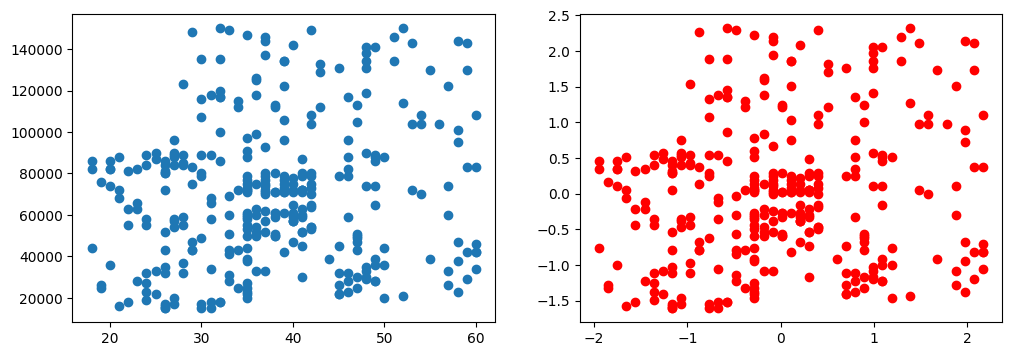

In [63]:
fig, ax = plt.subplots(1, 2, figsize = (12, 4))
ax[0].scatter(X_train['Age'], X_train['EstimatedSalary'])
ax[1].scatter(scaled['Age'], scaled['EstimatedSalary'], color = 'r')

<Axes: xlabel='Age', ylabel='Density'>

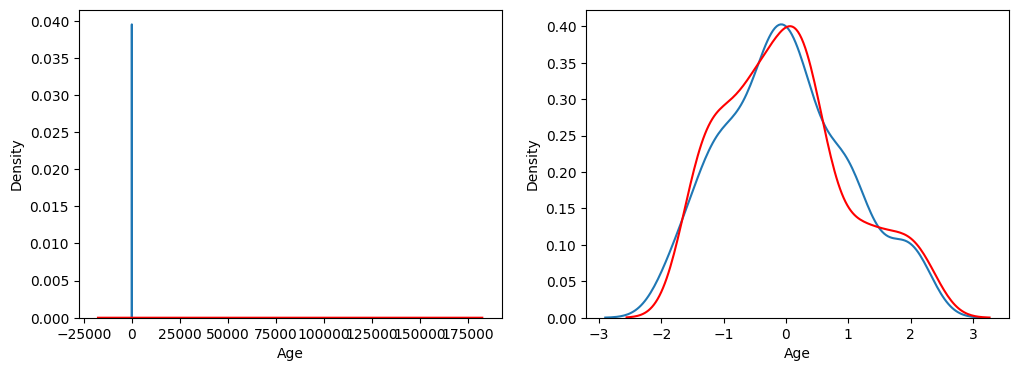

In [72]:
fig, ax = plt.subplots(1, 2, figsize = (12, 4))
import seaborn as sns
sns.kdeplot(data = X_train['Age'], ax = ax[0])
sns.kdeplot(data = X_train['EstimatedSalary'], ax = ax[0], color = 'r')

sns.kdeplot(data = scaled['Age'], ax = ax[1])
sns.kdeplot(data = scaled['EstimatedSalary'], ax = ax[1], color = 'r')